### Prepare data

In [1]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("data/raw")

# Load the main sales dataset
train = pd.read_csv(r"D:\Shrabani.Personal\Self_Project\forecastlab\data\raw\train.csv", parse_dates=["date"])

print("Dataset shape:", train.shape)
print("\nColumns:")
print(train.columns.tolist())

print("\nFirst five rows:")
print(train.head())

print("\nDate range:")
print(train["date"].min(), "to", train["date"].max())

print("\nMissing values:")
print(train.isnull().sum())

print("\nNumber of stores:", train["store_nbr"].nunique())
print("Number of product families:", train["family"].nunique())

Dataset shape: (3000888, 6)

Columns:
['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion']

First five rows:
   id       date  store_nbr      family  sales  onpromotion
0   0 2013-01-01          1  AUTOMOTIVE    0.0            0
1   1 2013-01-01          1   BABY CARE    0.0            0
2   2 2013-01-01          1      BEAUTY    0.0            0
3   3 2013-01-01          1   BEVERAGES    0.0            0
4   4 2013-01-01          1       BOOKS    0.0            0

Date range:
2013-01-01 00:00:00 to 2017-08-15 00:00:00

Missing values:
id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

Number of stores: 54
Number of product families: 33


Number of observations: 1684
Date range: 2013-01-01 00:00:00 to 2017-08-15 00:00:00
           date   sales
12   2013-01-01     0.0
1794 2013-01-02  2652.0
3576 2013-01-03  2121.0
5358 2013-01-04  2056.0
7140 2013-01-05  2216.0


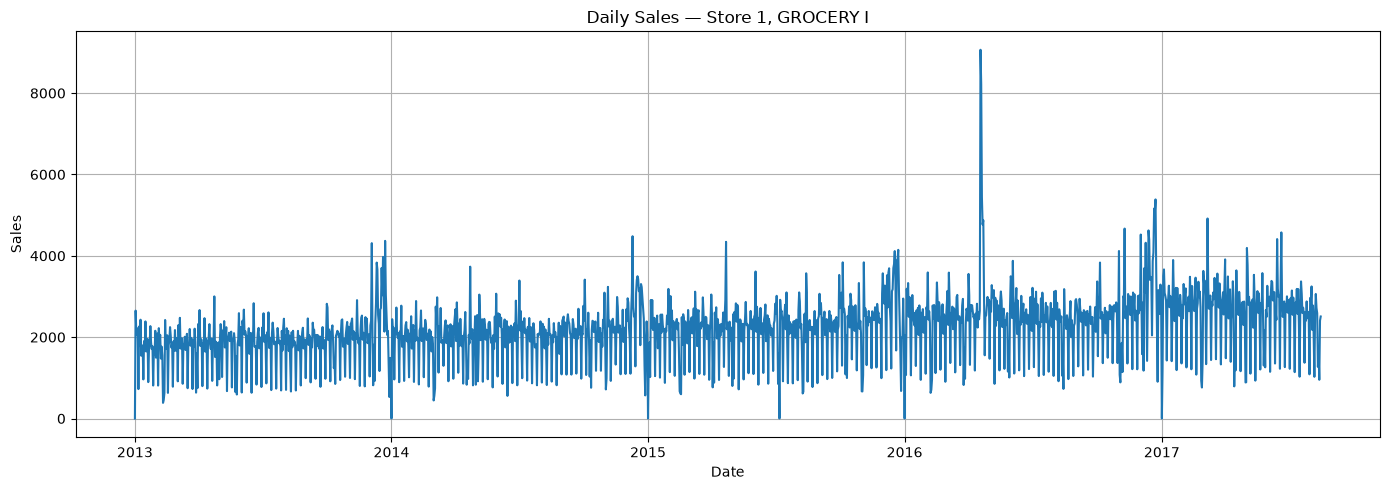

In [2]:
import matplotlib.pyplot as plt

# Select one store and product family
store_id = 1
family_name = "GROCERY I"

series = train[
    (train["store_nbr"] == store_id)
    & (train["family"] == family_name)
].copy()

# Sort chronologically
series = series.sort_values("date")

print("Number of observations:", len(series))
print("Date range:", series["date"].min(), "to", series["date"].max())
print(series[["date", "sales"]].head())

# Plot daily sales
plt.figure(figsize=(14, 5))
plt.plot(series["date"], series["sales"])
plt.title(f"Daily Sales — Store {store_id}, {family_name}")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid(True)
plt.tight_layout()
plt.show()

In [3]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Ensure chronological order
series = series.sort_values("date").reset_index(drop=True)

# Use the last 28 days for validation
horizon = 28
train_series = series.iloc[:-horizon].copy()
valid_series = series.iloc[-horizon:].copy()

# Seasonal-naive forecast: repeat the previous 7-day pattern
last_week = train_series["sales"].iloc[-7:].to_numpy()
baseline_forecast = np.tile(last_week, 4)

actual = valid_series["sales"].to_numpy()

# Evaluate
mae = mean_absolute_error(actual, baseline_forecast)
rmse = np.sqrt(mean_squared_error(actual, baseline_forecast))

print("Training observations:", len(train_series))
print("Validation observations:", len(valid_series))
print("Validation period:",
      valid_series["date"].min(), "to", valid_series["date"].max())
print(f"Seasonal-naive MAE:  {mae:.2f}")
print(f"Seasonal-naive RMSE: {rmse:.2f}")

Training observations: 1656
Validation observations: 28
Validation period: 2017-07-19 00:00:00 to 2017-08-15 00:00:00
Seasonal-naive MAE:  361.96
Seasonal-naive RMSE: 527.63


### Check the installed TimesFM version

In [4]:
import timesfm
from importlib.metadata import version

print("TimesFM package version:", version("timesfm"))
print("TimesFM module location:", timesfm.__file__)

TimesFM package version: 3.0.2
TimesFM module location: d:\Shrabani.Personal\Self_Project\forecastlab\.venv\Lib\site-packages\timesfm\__init__.py


### Check the TimesFM 3.0 API

In [5]:
import inspect
import timesfm

print("TimesFM module:", timesfm.__file__)
print("\nAvailable public names:")
print([name for name in dir(timesfm) if not name.startswith("_")])

TimesFM module: d:\Shrabani.Personal\Self_Project\forecastlab\.venv\Lib\site-packages\timesfm\__init__.py

Available public names:
['ForecastConfig', 'TimesFM3Forecaster', 'TimesFM3Torch', 'TimesFM_2p5_200M_torch', 'configs', 'timesfm_2p5', 'timesfm_2p5_torch', 'torch']


In [6]:
from importlib.metadata import distribution

dist = distribution("timesfm")
print(dist.read_text("METADATA").splitlines()[:25])

['Metadata-Version: 2.4', 'Name: timesfm', 'Version: 3.0.2', 'Summary: A time series foundation model.', 'Author-email: Rajat Sen <senrajat@google.com>, Yichen Zhou <yichenzhou@google.com>, Abhimanyu Das <abhidas@google.com>, Petros Mol <pmol@google.com>, Ayush Jain <ayuj@google.com>, Michael Chertushkin <chertushkinmichael@gmail.com>', 'License: Apache-2.0', 'Requires-Python: >=3.10', 'Description-Content-Type: text/markdown', 'License-File: LICENSE', 'Requires-Dist: numpy>=1.26.4', 'Requires-Dist: huggingface_hub>=0.28.0', 'Requires-Dist: safetensors>=0.5.3', 'Provides-Extra: torch', 'Requires-Dist: torch>=2.0.0; extra == "torch"', 'Provides-Extra: mlx', 'Requires-Dist: mlx>=0.32; extra == "mlx"', 'Requires-Dist: safetensors>=0.4.0; extra == "mlx"', 'Requires-Dist: huggingface-hub>=0.24.0; extra == "mlx"', 'Provides-Extra: flax', 'Requires-Dist: flax; extra == "flax"', 'Requires-Dist: optax; extra == "flax"', 'Requires-Dist: einshape; extra == "flax"', 'Requires-Dist: orbax-checkpoin

### Inspect the TimesFM 3.0 model interface

In [7]:
import inspect
from timesfm import TimesFM3Forecaster

print("Constructor:")
print(inspect.signature(TimesFM3Forecaster))

print("\nLoad pretrained model:")
print(inspect.signature(TimesFM3Forecaster.from_pretrained))

print("\nPrediction method:")
print(inspect.signature(TimesFM3Forecaster.predict))

Constructor:
(config: '_ModelConfig | None' = None, **kwargs)

Load pretrained model:
(pretrained_model_name_or_path: 'str' = 'google/timesfm-3.0-pytorch', device: 'str | None' = None, **kwargs: 'Any') -> 'TimesFM3Forecaster'

Prediction method:
(self, context: 'np.ndarray', horizon: 'int', past_only_covariates: 'np.ndarray | None' = None, past_future_covariates: 'np.ndarray | None' = None, ts_id: 'str | None' = None, return_quantiles: 'bool' = False, use_symmetric_averaging: 'bool' = False, make_positive: 'bool' = False, sort_quantiles: 'bool' = True, use_znorm: 'bool' = False, padding_mode: 'str' = 'none') -> 'ForecastOutput'


### load the pretrained model

In [8]:
from timesfm import TimesFM3Forecaster

model = TimesFM3Forecaster.from_pretrained(
    "google/timesfm-3.0-pytorch",
    device="cpu"
)

print("TimesFM 3.0 model loaded successfully.")

TimesFM 3.0 model loaded successfully.


### Forecast the next 28 days

In [9]:
# Prepare historical sales data for TimesFM
context = train_series["sales"].to_numpy(dtype="float32")

# Forecast the next 28 days
forecast_output = model.predict(
    context=context,
    horizon=28
)

print("Forecast generated successfully!")
print("Output type:", type(forecast_output))
print("Historical observations:", len(context))

Forecast generated successfully!
Output type: <class 'timesfm3.torch.timesfm3_forecaster.ForecastOutput'>
Historical observations: 1656


In [10]:
print("Forecast output fields:")
print(forecast_output)

print("\nForecast output attributes:")
print(vars(forecast_output).keys())

Forecast output fields:
ForecastOutput(ts_id=None, forecast=array([3132.2131, 2714.3289, 2816.5486, 2663.536 , 1219.8037, 2646.947 ,
       2878.7473, 3023.0913, 2621.7734, 2863.0132, 2663.0972, 1179.0793,
       2697.8254, 2879.3823, 2997.0046, 2667.6663, 2844.005 , 2691.7969,
       1228.4738, 2658.764 , 2866.218 , 2996.5293, 2678.0596, 2838.6155,
       2613.0767, 1187.852 , 2600.4614, 2846.1948], dtype=float32), quantiles=None)

Forecast output attributes:
dict_keys(['ts_id', 'forecast', 'quantiles'])


### Calculate TimesFM performance

In [11]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Extract the 28 forecasted sales values
timesfm_forecast = np.asarray(
    forecast_output.forecast
).reshape(-1)[:28]

# Actual sales for the same 28 validation days
actual = valid_series["sales"].to_numpy()

# Evaluate TimesFM
timesfm_mae = mean_absolute_error(actual, timesfm_forecast)
timesfm_rmse = np.sqrt(
    mean_squared_error(actual, timesfm_forecast)
)

print("TimesFM MAE:", round(timesfm_mae, 2))
print("TimesFM RMSE:", round(timesfm_rmse, 2))
print("Forecast horizon:", len(timesfm_forecast))
print("Actual observations:", len(actual))

TimesFM MAE: 278.98
TimesFM RMSE: 425.35
Forecast horizon: 28
Actual observations: 28


### Compare against our baseline

In [12]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Seasonal Naive", "TimesFM 3.0"],
    "MAE": [mae, timesfm_mae],
    "RMSE": [rmse, timesfm_rmse]
})

display(comparison.round(2))

,Model,MAE,RMSE
0,Seasonal Naive,361.96,527.63
1,TimesFM 3.0,278.98,425.35


## Initial Benchmark Results

We evaluated **TimesFM 3.0** against a seasonal-naive baseline for 28-day retail sales forecasting using the Kaggle Store Sales – Time Series Forecasting dataset.

**Evaluation setup**
- **Store:** 1
- **Product family:** GROCERY I
- **Historical observations:** 1,656
- **Forecast horizon:** 28 days
- **Approach:** Zero-shot forecasting with pretrained TimesFM 3.0
- **Metrics:** Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE)

### Model Comparison

| Model | MAE | RMSE |
|---|---:|---:|
| Seasonal Naive | 361.96 | 527.63 |
| **TimesFM 3.0** | **278.98** | **425.35** |
| Improvement | **22.9%** | **19.2%** |

### Key Findings

- **22.9% lower MAE:** TimesFM reduced the average absolute forecasting error compared with the seasonal-naive baseline.
- **19.2% lower RMSE:** TimesFM also reduced the penalty associated with larger prediction errors.
- **Zero-shot forecasting:** TimesFM generated predictions using historical sales data without fine-tuning on this retail dataset.

### Conclusion

In this initial experiment, pretrained TimesFM 3.0 outperformed the seasonal-naive baseline on both evaluation metrics. These results suggest that the foundation model can provide useful forecasts for this particular retail sales series.

However, the findings are limited to one store, one product family, and one 28-day validation period. Further evaluation across multiple stores, product families, and forecast periods is needed to assess the model's generalization.

**Next steps:** Visualize actual versus predicted sales, evaluate additional time series, and document the experimental setup to ensure reproducibility.

### Visualize the forecasts

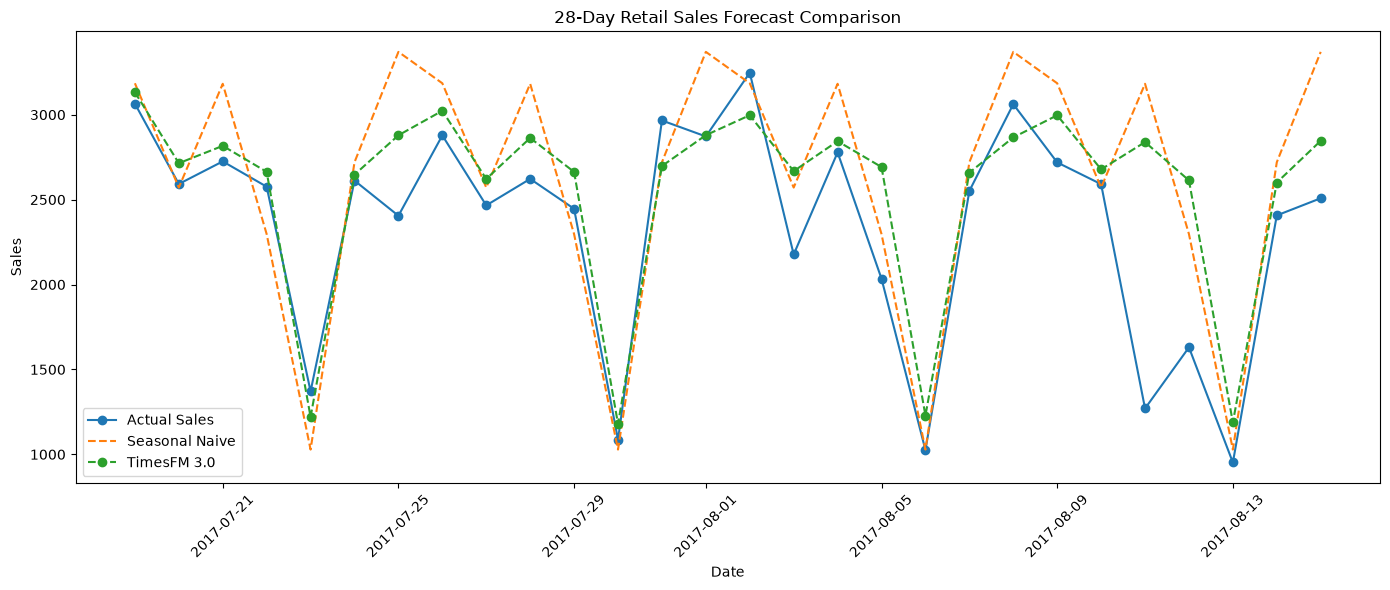

In [13]:
import matplotlib.pyplot as plt
import pandas as pd

forecast_dates = valid_series["date"]

plt.figure(figsize=(14, 6))

plt.plot(
    forecast_dates,
    actual,
    label="Actual Sales",
    marker="o"
)

plt.plot(
    forecast_dates,
    baseline_forecast,
    label="Seasonal Naive",
    linestyle="--"
)

plt.plot(
    forecast_dates,
    timesfm_forecast,
    label="TimesFM 3.0",
    linestyle="--",
    marker="o"
)

plt.title("28-Day Retail Sales Forecast Comparison")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### ForecastLab — multi-series evaluation

In [14]:
print("Number of stores:", train["store_nbr"].nunique())
print("Number of product families:", train["family"].nunique())

print("\nSales by store and product family:")
display(
    train.groupby(["store_nbr", "family"])["sales"]
    .count()
    .reset_index(name="observations")
    .head(10)
)

Number of stores: 54
Number of product families: 33

Sales by store and product family:


,store_nbr,family,observations
0,1,AUTOMOTIVE,1684
1,1,BABY CARE,1684
2,1,BEAUTY,1684
3,1,BEVERAGES,1684
4,1,BOOKS,1684
5,1,BREAD/BAKERY,1684
6,1,CELEBRATION,1684
7,1,CLEANING,1684
8,1,DAIRY,1684
9,1,DELI,1684


### Select the evaluation series
Add a new Code cell in 01_data_explorati

In [15]:
# Select five store–family combinations
evaluation_series = [
    (1, "GROCERY I"),
    (1, "BEVERAGES"),
    (1, "DAIRY"),
    (10, "GROCERY I"),
    (20, "BEVERAGES"),
]

for store_id, family_name in evaluation_series:
    subset = train[
        (train["store_nbr"] == store_id)
        & (train["family"] == family_name)
    ].sort_values("date")

    print(
        f"Store {store_id} | {family_name} | "
        f"{len(subset)} observations | "
        f"Mean sales: {subset['sales'].mean():.2f}"
    )

Store 1 | GROCERY I | 1684 observations | Mean sales: 2223.17
Store 1 | BEVERAGES | 1684 observations | Mean sales: 1587.75
Store 1 | DAIRY | 1684 observations | Mean sales: 626.10
Store 10 | GROCERY I | 1684 observations | Mean sales: 2450.25
Store 20 | BEVERAGES | 1684 observations | Mean sales: 1639.48


### Evaluate both models across all five series.

In [16]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

results = []

for store_id, family_name in evaluation_series:
    subset = (
        train[
            (train["store_nbr"] == store_id)
            & (train["family"] == family_name)
        ]
        .sort_values("date")
        .reset_index(drop=True)
    )

    # Use the last 28 days for validation
    context = subset["sales"].iloc[:-28].to_numpy(dtype="float32")
    actual = subset["sales"].iloc[-28:].to_numpy()

    # Seasonal-naive forecast: repeat the last 7 days four times
    last_week = context[-7:]
    baseline_forecast = np.tile(last_week, 4)

    # TimesFM zero-shot forecast
    forecast_output = model.predict(
        context=context,
        horizon=28
    )
    timesfm_forecast = np.asarray(
        forecast_output.forecast
    ).reshape(-1)[:28]

    # Calculate metrics
    results.append({
        "Store": store_id,
        "Family": family_name,
        "Baseline MAE": mean_absolute_error(
            actual, baseline_forecast
        ),
        "TimesFM MAE": mean_absolute_error(
            actual, timesfm_forecast
        ),
        "Baseline RMSE": np.sqrt(
            mean_squared_error(actual, baseline_forecast)
        ),
        "TimesFM RMSE": np.sqrt(
            mean_squared_error(actual, timesfm_forecast)
        ),
    })

results_df = pd.DataFrame(results)

display(results_df.round(2))

,Store,Family,Baseline MAE,TimesFM MAE,Baseline RMSE,TimesFM RMSE
0,1,GROCERY I,361.96,278.98,527.63,425.35
1,1,BEVERAGES,225.11,248.94,364.11,372.33
2,1,DAIRY,84.50,72.55,118.95,109.96
3,10,GROCERY I,522.14,260.58,656.32,326.44
4,20,BEVERAGES,776.11,711.95,936.08,921.28


### Calculate improvement for each series

In [17]:
results_df["MAE Improvement (%)"] = (
    (results_df["Baseline MAE"] - results_df["TimesFM MAE"])
    / results_df["Baseline MAE"] * 100
)

results_df["RMSE Improvement (%)"] = (
    (results_df["Baseline RMSE"] - results_df["TimesFM RMSE"])
    / results_df["Baseline RMSE"] * 100
)

display(
    results_df[
        ["Store", "Family", "MAE Improvement (%)", "RMSE Improvement (%)"]
    ].round(2)
)

print(
    "Average MAE improvement:",
    round(results_df["MAE Improvement (%)"].mean(), 2), "%"
)

print(
    "Average RMSE improvement:",
    round(results_df["RMSE Improvement (%)"].mean(), 2), "%"
)

,Store,Family,MAE Improvement (%),RMSE Improvement (%)
0,1,GROCERY I,22.93,19.38
1,1,BEVERAGES,-10.59,-2.26
2,1,DAIRY,14.14,7.56
3,10,GROCERY I,50.09,50.26
4,20,BEVERAGES,8.27,1.58


Average MAE improvement: 16.97 %
Average RMSE improvement: 15.31 %
